<a href="https://colab.research.google.com/github/ronanorsomething/DATA201-labs/blob/main/Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mount drive
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV
)

from sklearn.preprocessing import (
    OneHotEncoder, StandardScaler, MinMaxScaler,
    RobustScaler, Normalizer, KBinsDiscretizer,
    FunctionTransformer
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import  (confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

drive.mount ('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

# sep = ";" added to prevent reading as one column
bank = pd.read_csv("/content/drive/MyDrive/Data 201/Datasets/bank.csv", sep = ";")
bank

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4516,33,services,married,secondary,no,-333,yes,no,cellular,30,jul,329,5,-1,0,unknown,no
4517,57,self-employed,married,tertiary,yes,-3313,yes,yes,unknown,9,may,153,1,-1,0,unknown,no
4518,57,technician,married,secondary,no,295,no,no,cellular,19,aug,151,11,-1,0,unknown,no
4519,28,blue-collar,married,secondary,no,1137,no,no,cellular,6,feb,129,4,211,3,other,no


In [ ]:
bank.shape

(4521, 17)

Each row of the dataset represents an individual client that was contacted by the bank directly for advertising purposes. We are aiming to predict whether a client will subscribe a term deposit, represented by the target variable "y".

Variable descriptions from the dataset page:

# Input variables:

   ## Bank client data:
   
   1 - age (numeric)

   2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student",
                                       "blue-collar","self-employed","retired","technician","services")
   
   3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)
  
   4 - education (categorical: "unknown","secondary","primary","tertiary")
   
   5 - **default: has credit in default? (binary: "yes","no")**
  
   6 - **balance: average yearly balance, in euros (numeric)**
  
   7 - housing: has housing loan? (binary: "yes","no")
  
   8 - **loan: has personal loan? (binary: "yes","no")**
   
   ## Related with the last contact of the current campaign:
   
  9 - contact: contact communication type (categorical: "unknown","telephone","cellular")
  
  10 - day: last contact day of the month (numeric)
  
  11 - month: last contact month of year (categorical: "jan", "feb",
  "mar", ..., "nov", "dec")
  
  12 - duration: last contact duration, in seconds (numeric)
  
  ## Other attributes:
  
  13 - **campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)**
  
  14 - **pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)**
  
  15 - **previous: number of contacts performed before this campaign and for this client (numeric)**
  
  16 - **poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")**

  ## Output variable (desired target):

  17 - y - has the client subscribed a term deposit? (binary: "yes","no")

The predictors that will be used are default, balance, loan, campaign, pdays, previous, and poutcome
# Distribution of target variable:

In [ ]:
bank['y'].value_counts()

,count
y,
no,4000
yes,521


Out of 4521 clients, 521 decided to subscribe a deposit to the bank, meaning that this dataset is highly imbalanced.

In the context of the dataset, a false positive would be predicting that a person would subscribe when they would not, and a false negative would be predicting that a person would not subscribe when they would have. A false negative would be more concerning, because this would mean that the bank loses a potential customer whereas a false positive doesn't lose the bank anything.

# Checking for NA values

In [ ]:
print(bank.isna().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [ ]:
X = bank[['default', 'balance', 'loan', 'campaign', 'pdays', 'previous', 'poutcome']]
y = bank['y']

numeric_features = ['balance', 'campaign', 'pdays', 'previous']
categorical_features = ['default', 'loan', 'poutcome']

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),

    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.15,
    stratify = y,
    random_state = 0
)

kfold = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 0
    )
cv_scores = cross_val_score(
    LogisticRegression(random_state = 0),
    preprocess.fit_transform(X_train),
    y_train,
    cv = kfold,
    scoring = "roc_auc"
)
print(cv_scores)
print(cv_scores.mean())

[0.67205882 0.55640284 0.69134358 0.62870989 0.64106171]
0.6379153696481699


In [ ]:
X_train_transformed = preprocess.fit_transform(X_train)

X_test_transformed = preprocess.transform(X_test)

print("X_train_transformed shape:", X_train_transformed.shape)
print("X_test_transformed shape:", X_test_transformed.shape)

X_test.shape

X_train_transformed shape: (3842, 12)
X_test_transformed shape: (679, 12)


(679, 7)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

log_reg = make_pipeline(
    preprocess,
    LogisticRegression(max_iter=2000)
)
log_reg.fit(X_train, y_train)
log_reg_preds = log_reg.predict(X_test)
print(f"Logistic Regression Test Accuracy: {accuracy_score(y_test, log_reg_preds):.4f}")


Logistic Regression Test Accuracy: 0.8925


In [ ]:
lda = make_pipeline(
    preprocess,
    LinearDiscriminantAnalysis()
)
lda.fit(X_train, y_train)
lda_preds = lda.predict(X_test)
print(f"LDA Test Accuracy: {accuracy_score(y_test, lda_preds):.4f}")

LDA Test Accuracy: 0.8925


In [ ]:
qda = make_pipeline(
    preprocess,
    QuadraticDiscriminantAnalysis()
)
qda.fit(X_train, y_train)
qda_preds = qda.predict(X_test)
print(f"QDA Test Accuracy: {accuracy_score(y_test, qda_preds):.4f}")

QDA Test Accuracy: 0.8616


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


0.8924889543446245


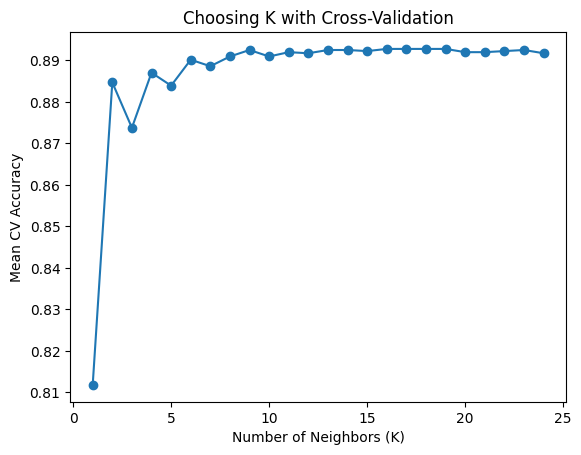

In [ ]:
k_values = list(range(1, 25))
knn_cv_scores = []


for k in k_values:

    model = make_pipeline(
        preprocess,
        KNeighborsClassifier(n_neighbors=k)
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5
    )

    knn_cv_scores.append(scores.mean())

best_knn = make_pipeline(
    preprocess,
    KNeighborsClassifier(n_neighbors=9)
)

best_knn.fit(X_train, y_train)
best_knn_pred = best_knn.predict(X_test)

print(accuracy_score(y_test, best_knn_pred))





# Plot K vs. Cross-validation performance
plt.plot(
    k_values,
    knn_cv_scores,
    marker="o"
)
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
plt.title("Choosing K with Cross-Validation")

plt.show()

In [ ]:
#Default threshold of 0.5
logreg_cm = confusion_matrix(y_test, log_reg_preds)
lda_cm = confusion_matrix(y_test, lda_preds)
qda_cm = confusion_matrix(y_test, qda_preds)
knn_cm = confusion_matrix(y_test, best_knn_pred)
print("Logistic regression confusion matrix")
print(logreg_cm)
print("Lda confusion matrix")
print(lda_cm)
print("Qda confusion matrix")
print(qda_cm)
print("Knn confusion matrix")
print(knn_cm)

Logistic regression confusion matrix
[[593   8]
 [ 65  13]]
Lda confusion matrix
[[593   8]
 [ 65  13]]
Qda confusion matrix
[[568  33]
 [ 61  17]]
Knn confusion matrix
[[596   5]
 [ 68  10]]


For my threshold, I chose 0.2 to minimize the number of false negatives, as those are the most detrimental to the bank.

In [ ]:
threshold = 0.2
logreg_probs = log_reg.predict_proba(X_test)[:, 1]
knn_probs = best_knn.predict_proba(X_test)[:, 1]

lda_probs = lda.predict_proba(X_test)[:, 1]
qda_probs = qda.predict_proba(X_test)[:, 1]

logreg_pred_20 = np.where(logreg_probs >= threshold, "yes", "no")
lda_pred_20 = np.where(lda_probs >= threshold, "yes", "no")
qda_pred_20 = np.where(qda_probs >= threshold, "yes", "no")
knn_pred_20 = np.where(knn_probs >= threshold, "yes", "no")

logreg_cm = confusion_matrix(y_test, logreg_pred_20, labels=["no", "yes"])
lda_cm = confusion_matrix(y_test, lda_pred_20, labels=["no", "yes"])
qda_cm = confusion_matrix(y_test, qda_pred_20, labels=["no", "yes"])
knn_cm = confusion_matrix(y_test, knn_pred_20, labels=["no", "yes"])

print("Logistic regression confusion matrix")
print(logreg_cm)
print("\nLda confusion matrix")
print(lda_cm)
print("\nQda confusion matrix")
print(qda_cm)
print("\nKnn confusion matrix")
print(knn_cm)

Logistic regression confusion matrix
[[590  11]
 [ 61  17]]

Lda confusion matrix
[[592   9]
 [ 64  14]]

Qda confusion matrix
[[565  36]
 [ 61  17]]

Knn confusion matrix
[[508  93]
 [ 44  34]]


In [ ]:
#Logistic regression
print("Logistic regression accuracy:")
print(accuracy_score(y_test, logreg_pred_20))
print("Logistic regression precision:")
print(precision_score(y_test, logreg_pred_20, pos_label="yes"))
print("Logistic regression recall:")
print(recall_score(y_test, logreg_pred_20, pos_label="yes"))
print("Logistic regression specificity:")
print(logreg_cm[0, 0] / (logreg_cm[0, 0] + logreg_cm[0, 1]))
print("Logistic regression f1:")
print(f1_score(y_test, logreg_pred_20, pos_label="yes"))
print("Logistic regression roc-auc:")
print(roc_auc_score(y_test, logreg_probs))
#LDA
print("\nLDA accuracy:")
print(accuracy_score(y_test, lda_pred_20))
print("LDA precision:")
print(precision_score(y_test, lda_pred_20, pos_label="yes"))
print("LDA recall:")
print(recall_score(y_test, lda_pred_20, pos_label="yes"))
print("LDA specificity:")
print(lda_cm[0, 0] / (lda_cm[0, 0] + lda_cm[0, 1]))
print("LDA f1:")
print(f1_score(y_test, lda_pred_20, pos_label="yes"))
print("LDA roc-auc:")
print(roc_auc_score(y_test, lda_probs))
#QDA
print("\nQDA accuracy:")
print(accuracy_score(y_test, qda_pred_20))
print("QDA precision:")
print(precision_score(y_test, qda_pred_20, pos_label="yes"))
print("QDA recall:")
print(recall_score(y_test, qda_pred_20, pos_label="yes"))
print("QDA specificity:")
print(qda_cm[0, 0] / (qda_cm[0, 0] + qda_cm[0, 1]))
print("QDA f1:")
print(f1_score(y_test, qda_pred_20, pos_label="yes"))
print("QDA roc-auc:")
print(roc_auc_score(y_test, qda_probs))
#KNN
print("\nKNN accuracy:")
print(accuracy_score(y_test, knn_pred_20))
print("KNN precision:")
print(precision_score(y_test, knn_pred_20, pos_label="yes"))
print("KNN recall:")
print(recall_score(y_test, knn_pred_20, pos_label="yes"))
print("KNN specificity:")
print(knn_cm[0, 0] / (knn_cm[0, 0] + knn_cm[0, 1]))
print("KNN f1:")
print(f1_score(y_test, knn_pred_20, pos_label="yes"))
print("KNN roc-auc:")
print(roc_auc_score(y_test, knn_probs))

Logistic regression accuracy:
0.8939617083946981
Logistic regression precision:
0.6071428571428571
Logistic regression recall:
0.21794871794871795
Logistic regression specificity:
0.9816971713810316
Logistic regression f1:
0.32075471698113206
Logistic regression roc-auc:
0.6396923930201801

LDA accuracy:
0.8924889543446245
LDA precision:
0.6086956521739131
LDA recall:
0.1794871794871795
LDA specificity:
0.9850249584026622
LDA f1:
0.27722772277227725
LDA roc-auc:
0.645942659669781

QDA accuracy:
0.8571428571428571
QDA precision:
0.32075471698113206
QDA recall:
0.21794871794871795
QDA specificity:
0.940099833610649
QDA f1:
0.2595419847328244
QDA roc-auc:
0.6132087546397031

KNN accuracy:
0.7982326951399117
KNN precision:
0.2677165354330709
KNN recall:
0.4358974358974359
KNN specificity:
0.8452579034941764
KNN f1:
0.33170731707317075
KNN roc-auc:
0.6566619736336875




|Model| Accuracy | Precision | Recall | Specificity | F1 | ROC-AUC |
|-----|----------|-----------|--------|-------------|----|---------|
| Logistic Regression| 0.8940 | 0.6071 | 0.2179 | 0.9817 |0.3208 | 0.6397 |
| LDA | 0.8925 | 0.6087 | 0.1795 | 0.9850 | 0.2772 | 0.6459 |
| QDA | 0.8571 | 0.3208 | 0.2179 | 0.9401 | 0.2595 | 0.6132 |
| KNN | 0.7982 | 0.2677 | 0.4359 | 0.8453 | 0.3317 | 0.6567 |

Because the goal is to minimize false negatives in order to attract as many customers as posssible, I chose KNN as my model of choice. The false positives are not really an issue for the bank as calls do not cost anything to make, so the low accuracy and precision isn't important. This means that specificity is the most important metric to measure.


In [ ]:
y_test_binary = np.where(
    y_test == "Yes",
    1,
    0
)

#calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    prob_yes
)

#plot
plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

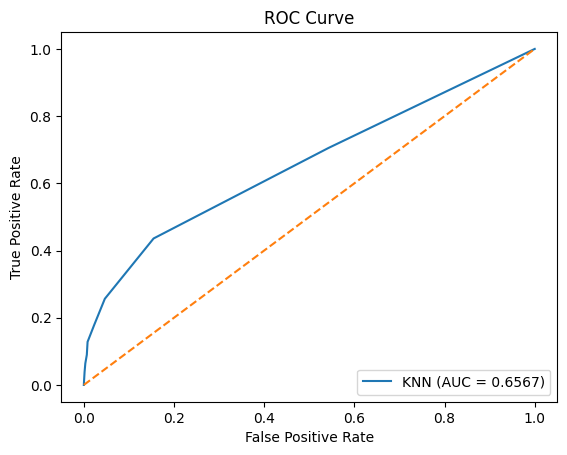

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    knn_probs,
    pos_label="yes"
)

plt.plot(
    fpr,
    tpr,
    label="KNN (AUC = %0.4f)" % roc_auc_score(y_test, knn_probs)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

plt.show()